In [1]:
import pandas as pd

In [2]:
propensity_df = pd.read_feather("Propensity_Data.ftr")

sf_master_df = pd.read_feather("sf_master.ftr")

In [3]:
sf_master_df["object_type"].unique()

array(['Order'], dtype=object)

In [4]:
sf_master_df
propensity_df.info()
sf_master_df.info()

<class 'pandas.core.frame.DataFrame'>
Index: 3680 entries, 0 to 3679
Data columns (total 25 columns):
 #   Column                         Non-Null Count  Dtype 
---  ------                         --------------  ----- 
 0   Customer_ID                    3680 non-null   int64 
 1   Account_Status                 3680 non-null   object
 2   Is_National_Account            3680 non-null   object
 3   Is_Washington                  3680 non-null   object
 4   Is_Tribal                      3680 non-null   object
 5   Is_VLT                         3680 non-null   object
 6   State_Code                     3372 non-null   object
 7   Postal_Code                    3680 non-null   object
 8   Country                        3680 non-null   object
 9   Jurisdiction_Name              3680 non-null   object
 10  CBSA                           3680 non-null   object
 11  Seasonality_Segment            2507 non-null   object
 12  Max_Quarter_Year_1             3680 non-null   object
 13  Max_Quar

In [5]:
propensity_df.isna().sum()
propensity_df["State_Code"].unique()
propensity_df["Seasonality_Segment"].unique()
propensity_df["EA_Segment"].unique()
propensity_df["Density_Segment"].unique()
propensity_df["Parent_Influence_Slots_Bucket"].unique()

array(['M', 'L', 'No bucket', None], dtype=object)

In [6]:
propensity_df["Customer_ID"].value_counts() # Al the customers are unique
propensity_df["State_Code"].unique()
#propensity_df["State_Code"].isnull().sum()
#propensity_df["State_Code"].fillna(propensity_df["State_Code"].mode())
propensity_df["State_Code"].value_counts()

State_Code
NV                  781
OK                  631
CA                  235
No Address Found    220
FL                  215
WA                  128
LA                   79
IL                   77
KS                   70
NM                   67
SD                   54
BC                   46
ON                   41
CO                   41
MT                   38
AZ                   37
MS                   36
AB                   34
NY                   33
ND                   33
MI                   32
NE                   32
WI                   28
IA                   28
PR                   27
TX                   26
MN                   26
PA                   24
IN                   19
NJ                   18
KY                   18
OH                   16
MO                   15
QC                   13
SK                   13
TN                   12
OR                   12
NH                   10
MD                    9
AL                    9
VA                    9
MB   

In [7]:
"""
Total records: 3,860
No address available: 220
NULL: 308
Therefore, address information is unavailable for 528 records, which is about 13.7% of the dataset.
220+308=528

(528/3860)*100=13.7% 

So 13.7% is not a tiny amount.
so we will fill those rows with NO Adress found values so no data is lost and it doesn't affect our prediction further
"""

propensity_df["State_Code"] = propensity_df["State_Code"].fillna(
    "No address available"
)

In [8]:
propensity_df["State_Code"].isna().sum()
propensity_df.info()

<class 'pandas.core.frame.DataFrame'>
Index: 3680 entries, 0 to 3679
Data columns (total 25 columns):
 #   Column                         Non-Null Count  Dtype 
---  ------                         --------------  ----- 
 0   Customer_ID                    3680 non-null   int64 
 1   Account_Status                 3680 non-null   object
 2   Is_National_Account            3680 non-null   object
 3   Is_Washington                  3680 non-null   object
 4   Is_Tribal                      3680 non-null   object
 5   Is_VLT                         3680 non-null   object
 6   State_Code                     3680 non-null   object
 7   Postal_Code                    3680 non-null   object
 8   Country                        3680 non-null   object
 9   Jurisdiction_Name              3680 non-null   object
 10  CBSA                           3680 non-null   object
 11  Seasonality_Segment            2507 non-null   object
 12  Max_Quarter_Year_1             3680 non-null   object
 13  Max_Quar

##Seasonality_Segment    



In [9]:
propensity_df["Seasonality_Segment"].value_counts()
#propensity_df["Seasonality_Segment"].isna().sum()

"""
It would be better if we combine the None and Null values
as Unknown category due to which we can handle null values 

"""

'\nIt would be better if we combine the None and Null values\nas Unknown category due to which we can handle null values \n\n'

In [10]:
propensity_df["Seasonality_Segment"] = (
    propensity_df["Seasonality_Segment"]
    .fillna("Unknown")
    .replace("None", "Unknown")
) 

propensity_df["Seasonality_Segment"].isna().sum()
propensity_df["Seasonality_Segment"].value_counts()

propensity_df.info()

<class 'pandas.core.frame.DataFrame'>
Index: 3680 entries, 0 to 3679
Data columns (total 25 columns):
 #   Column                         Non-Null Count  Dtype 
---  ------                         --------------  ----- 
 0   Customer_ID                    3680 non-null   int64 
 1   Account_Status                 3680 non-null   object
 2   Is_National_Account            3680 non-null   object
 3   Is_Washington                  3680 non-null   object
 4   Is_Tribal                      3680 non-null   object
 5   Is_VLT                         3680 non-null   object
 6   State_Code                     3680 non-null   object
 7   Postal_Code                    3680 non-null   object
 8   Country                        3680 non-null   object
 9   Jurisdiction_Name              3680 non-null   object
 10  CBSA                           3680 non-null   object
 11  Seasonality_Segment            3680 non-null   object
 12  Max_Quarter_Year_1             3680 non-null   object
 13  Max_Quar

In [11]:
## Lets handle the EA segment

propensity_df["EA_Segment"].value_counts()
#propensity_df["EA_Segment"].isna().sum()

propensity_df["EA_Segment"] = (
    propensity_df["EA_Segment"]
    .fillna("Unknown")
    .replace("None", "Unknown")
)

In [12]:
# Lets Hnadle Density segment 

propensity_df["Density_Segment"].value_counts()
#propensity_df["Density_Segment"].isna().sum()

propensity_df["Density_Segment"] = (
    propensity_df["Density_Segment"]
    .fillna("Unknown")
    .replace("-", "Unknown")
)

In [13]:
#propensity_df.info()

# Lets Handle  Parent_Influence_Slots_Bucket
# How influential is the parent company/group behind 
#this casino,based on the number of slots associated 
#with that parent?
#
propensity_df["Parent_Influence_Slots_Bucket"].value_counts()

propensity_df["Parent_Influence_Slots_Bucket"].isna().sum()

179

In [14]:
propensity_df["Parent_Influence_Slots_Bucket"] = (
    propensity_df["Parent_Influence_Slots_Bucket"]
    .fillna("Unknown")
    .replace({
        "M": "Medium Bucket",
        "L": "Low Bucket"
    })
)

"""
Filling with unknown values cause we don't know wether they
are Non bucket , Medium , or low 
"""

"\nFilling with unknown values cause we don't know wether they\nare Non bucket , Medium , or low \n"

In [15]:
propensity_df["Parent_Influence_Slots_Bucket"].value_counts()

Parent_Influence_Slots_Bucket
Medium Bucket    2100
Low Bucket        821
No bucket         580
Unknown           179
Name: count, dtype: int64

In [16]:
#ALL THE NULL VALUES ARE HANDLED WELL 
propensity_df.isna().sum()


Customer_ID                      0
Account_Status                   0
Is_National_Account              0
Is_Washington                    0
Is_Tribal                        0
Is_VLT                           0
State_Code                       0
Postal_Code                      0
Country                          0
Jurisdiction_Name                0
CBSA                             0
Seasonality_Segment              0
Max_Quarter_Year_1               0
Max_Quarter_Year_2               0
EA_Segment                       0
Revenue_Bucket                   0
Profit_Bucket                    0
Market_Share_Segment             0
Casino_Size_Segment              0
Market_Potential_Segment         0
Churn_Segment                    0
Competitiveness_Flag             0
Volume_Segment                   0
Density_Segment                  0
Parent_Influence_Slots_Bucket    0
dtype: int64

In [17]:
## sf_master_df dataset

#sf_master_df.info()

sf_master_df["item_quantity"].value_counts()

sf_master_df["item_quantity"].describe()

sf_master_df["item_quantity"].isna().sum()

54

In [18]:
sf_master_df["item_quantity"] = sf_master_df["item_quantity"].fillna(
    sf_master_df["item_quantity"].median()
)

In [19]:
sf_master_df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 9574 entries, 0 to 9573
Data columns (total 5 columns):
 #   Column             Non-Null Count  Dtype         
---  ------             --------------  -----         
 0   Customer_ID        9574 non-null   int64         
 1   object_type        9574 non-null   object        
 2   object_status      9574 non-null   object        
 3   sent_to_socp_date  9574 non-null   datetime64[ns]
 4   item_quantity      9574 non-null   float64       
dtypes: datetime64[ns](1), float64(1), int64(1), object(2)
memory usage: 374.1+ KB


## Data Validation

In [20]:
propensity_df.duplicated().sum()

sf_master_df.duplicated().sum()
"""
we got 548 initially duplicate rows in master_df
"""

'\nwe got 548 initially duplicate rows in master_df\n'

In [21]:
sf_master_df = sf_master_df.drop_duplicates()
sf_master_df.duplicated().sum()

0

In [22]:
propensity_df["Customer_ID"].nunique()

3680

In [23]:
sf_master_df.info()

<class 'pandas.core.frame.DataFrame'>
Index: 9026 entries, 0 to 9573
Data columns (total 5 columns):
 #   Column             Non-Null Count  Dtype         
---  ------             --------------  -----         
 0   Customer_ID        9026 non-null   int64         
 1   object_type        9026 non-null   object        
 2   object_status      9026 non-null   object        
 3   sent_to_socp_date  9026 non-null   datetime64[ns]
 4   item_quantity      9026 non-null   float64       
dtypes: datetime64[ns](1), float64(1), int64(1), object(2)
memory usage: 423.1+ KB


In [24]:
sf_master_df["Customer_ID"].nunique()

1090

In [25]:
sf_master_df.info()

<class 'pandas.core.frame.DataFrame'>
Index: 9026 entries, 0 to 9573
Data columns (total 5 columns):
 #   Column             Non-Null Count  Dtype         
---  ------             --------------  -----         
 0   Customer_ID        9026 non-null   int64         
 1   object_type        9026 non-null   object        
 2   object_status      9026 non-null   object        
 3   sent_to_socp_date  9026 non-null   datetime64[ns]
 4   item_quantity      9026 non-null   float64       
dtypes: datetime64[ns](1), float64(1), int64(1), object(2)
memory usage: 423.1+ KB


In [26]:
sf_master_df["object_type"].unique()

array(['Order'], dtype=object)

In [27]:
pd.crosstab(
    sf_master_df["object_type"],
    sf_master_df["object_status"]
)

object_status,Completed,Funnel
object_type,,
Order,7972,1054


In [28]:
"""
Customer/order is in the 
sales process but has not yet reached the completed stage.
"""

customer_status = pd.crosstab(
    sf_master_df["Customer_ID"],
    sf_master_df["object_status"]
)

print(customer_status.head())

object_status  Completed  Funnel
Customer_ID                     
10                     9       1
11                     5       0
12                    14       4
13                     3       0
14                    13       2


In [30]:
"""
            sf_master_df ====> complete understanding
            
object_status    Completed  Funnel
object_type
       Order        7972     1054

object_status  Completed  Funnel
Customer_ID                     
10                     9       1
11                     5       0
12                    14       4
13                     3       0
14                    13       2
Interpretation : The maximum orders are completed very very 
few orders are left in funnel/ not reached the completed stage

(7972/9026) * 100 = 88.3% orders are completed 
(1054/9026) * 100 = 11.7% orders are not completed 
This means maximum percentage orders are completed 

"""



'\n            sf_master_df ====> complete understanding\n            \nobject_status    Completed  Funnel\nobject_type\n       Order        7972     1054\n\nobject_status  Completed  Funnel\nCustomer_ID                     \n10                     9       1\n11                     5       0\n12                    14       4\n13                     3       0\n14                    13       2\nInterpretation : The maximum orders are completed very very \nfew orders are left in funnel/ not reached the completed stage\n\n(7972/9026) * 100 = 88.3% orders are completed \n(1054/9026) * 100 = 11.7% orders are not completed \nThis means maximum percentage orders are completed \n\n'

In [29]:
customer_summary = sf_master_df.groupby("Customer_ID").agg(
    total_orders=("Customer_ID", "count"),
    completed_orders=("object_status", lambda x: (x == "Completed").sum()),
    funnel_orders=("object_status", lambda x: (x == "Funnel").sum()),
    total_quantity=("item_quantity", "sum")
).reset_index()

customer_summary.head()

customer_summary["completion_rate"] = (
    customer_summary["completed_orders"]
    / customer_summary["total_orders"]
)

customer_summary.head()

print("Total Customers: ",len(customer_summary))

Total Customers:  1090


In [30]:
"""
Interpretation 
propensity_df
≈ 3,680 unique customers

sf_master_df
= 1,090 unique customers

So sf_master_df contains order/activity records 
for only 1,090 customers represented in that table.

But there's an important distinction:

We cannot yet say that the remaining ~2,590 customers 
definitely never ordered.

===> They simply don't have a record in sf_master_df.<====

"""

print("Propensity Customer_ID type:",
      propensity_df["Customer_ID"].dtype)

print("Customer Summary Customer_ID type:",
      customer_summary["Customer_ID"].dtype)

print("Propensity customers:",
      propensity_df["Customer_ID"].nunique())

print("Customer summary customers:",
      customer_summary["Customer_ID"].nunique())

Propensity Customer_ID type: int64
Customer Summary Customer_ID type: int64
Propensity customers: 3680
Customer summary customers: 1090


In [31]:
"""  
        MERGE THE BOTH TABLES
lETS DO LEFT JOIN 
CAUSE propensity_df is our left table 

"""

final_df = propensity_df.merge(
    customer_summary,
    on="Customer_ID",
    how="left"
)

In [32]:
final_df.head()

,Customer_ID,Account_Status,Is_National_Account,Is_Washington,Is_Tribal,Is_VLT,State_Code,Postal_Code,Country,Jurisdiction_Name,...,Churn_Segment,Competitiveness_Flag,Volume_Segment,Density_Segment,Parent_Influence_Slots_Bucket,total_orders,completed_orders,funnel_orders,total_quantity,completion_rate
0,1,Active,False,False,False,False,ON,L5N 2W8,CAN,AGCO - Ontario,...,None,Yes,High,High,Medium Bucket,NaN,NaN,NaN,NaN,NaN
1,2,Active,False,False,False,True,LA,70053,USA,None,...,None,-,Medium,Medium,Low Bucket,NaN,NaN,NaN,NaN,NaN
2,3,Active,False,False,False,True,LA,70068,USA,None,...,None,-,Medium,Medium,Low Bucket,NaN,NaN,NaN,NaN,NaN
3,4,Active,False,False,False,False,NV,89521,USA,None,...,None,Yes,High,High,No bucket,NaN,NaN,NaN,NaN,NaN
4,5,Active,False,False,False,False,NV,89431,USA,None,...,None,Yes,High,High,No bucket,NaN,NaN,NaN,NaN,NaN


In [33]:
"""
Assumption : No record in sf_master = customer has 
no historical order
"""

final_df["total_orders"] = final_df["total_orders"].fillna(0)
final_df["completed_orders"] = final_df["completed_orders"].fillna(0)
final_df["funnel_orders"] = final_df["funnel_orders"].fillna(0)
final_df["total_quantity"] = final_df["total_quantity"].fillna(0)
final_df["completion_rate"] = final_df["completion_rate"].fillna(0)

In [34]:
final_df

,Customer_ID,Account_Status,Is_National_Account,Is_Washington,Is_Tribal,Is_VLT,State_Code,Postal_Code,Country,Jurisdiction_Name,...,Churn_Segment,Competitiveness_Flag,Volume_Segment,Density_Segment,Parent_Influence_Slots_Bucket,total_orders,completed_orders,funnel_orders,total_quantity,completion_rate
0,1,Active,False,False,False,False,ON,L5N 2W8,CAN,AGCO - Ontario,...,None,Yes,High,High,Medium Bucket,0.0,0.0,0.0,0.0,0.0
1,2,Active,False,False,False,True,LA,70053,USA,None,...,None,-,Medium,Medium,Low Bucket,0.0,0.0,0.0,0.0,0.0
2,3,Active,False,False,False,True,LA,70068,USA,None,...,None,-,Medium,Medium,Low Bucket,0.0,0.0,0.0,0.0,0.0
3,4,Active,False,False,False,False,NV,89521,USA,None,...,None,Yes,High,High,No bucket,0.0,0.0,0.0,0.0,0.0
4,5,Active,False,False,False,False,NV,89431,USA,None,...,None,Yes,High,High,No bucket,0.0,0.0,0.0,0.0,0.0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
3675,3676,Inactive,False,False,False,True,IL,60563,USA,None,...,None,Yes,High,Medium,Low Bucket,0.0,0.0,0.0,0.0,0.0
3676,3677,Inactive,False,False,False,False,NV,89117,USA,None,...,None,Yes,High,High,Low Bucket,0.0,0.0,0.0,0.0,0.0
3677,3678,Inactive,False,False,False,False,MI,49969,USA,Michigan - Tribal,...,None,-,Low,Unknown,Medium Bucket,0.0,0.0,0.0,0.0,0.0
3678,3679,Active,False,False,False,False,No Address Found,None,No Address Found,Pennsylvania,...,None,-,-,Unknown,Medium Bucket,0.0,0.0,0.0,0.0,0.0


In [35]:
final_df.sample()
final_df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 3680 entries, 0 to 3679
Data columns (total 30 columns):
 #   Column                         Non-Null Count  Dtype  
---  ------                         --------------  -----  
 0   Customer_ID                    3680 non-null   int64  
 1   Account_Status                 3680 non-null   object 
 2   Is_National_Account            3680 non-null   object 
 3   Is_Washington                  3680 non-null   object 
 4   Is_Tribal                      3680 non-null   object 
 5   Is_VLT                         3680 non-null   object 
 6   State_Code                     3680 non-null   object 
 7   Postal_Code                    3680 non-null   object 
 8   Country                        3680 non-null   object 
 9   Jurisdiction_Name              3680 non-null   object 
 10  CBSA                           3680 non-null   object 
 11  Seasonality_Segment            3680 non-null   object 
 12  Max_Quarter_Year_1             3680 non-null   o

In [36]:
final_df.duplicated().sum()

0

In [37]:
"""
Separated Numerical and Categorical columns
To analyze them differently
"""
numeric_cols = final_df.select_dtypes(
    include=["int64", "float64"]
).columns

categorical_cols = final_df.select_dtypes(
    include=["object", "category"]
).columns

print("Numerical Columns:")
print(numeric_cols.tolist())

print("\nCategorical Columns:")
print(categorical_cols.tolist())

Numerical Columns:
['Customer_ID', 'total_orders', 'completed_orders', 'funnel_orders', 'total_quantity', 'completion_rate']

Categorical Columns:
['Account_Status', 'Is_National_Account', 'Is_Washington', 'Is_Tribal', 'Is_VLT', 'State_Code', 'Postal_Code', 'Country', 'Jurisdiction_Name', 'CBSA', 'Seasonality_Segment', 'Max_Quarter_Year_1', 'Max_Quarter_Year_2', 'EA_Segment', 'Revenue_Bucket', 'Profit_Bucket', 'Market_Share_Segment', 'Casino_Size_Segment', 'Market_Potential_Segment', 'Churn_Segment', 'Competitiveness_Flag', 'Volume_Segment', 'Density_Segment', 'Parent_Influence_Slots_Bucket']


In [38]:
final_df[numeric_cols].describe()

,Customer_ID,total_orders,completed_orders,funnel_orders,total_quantity,completion_rate
count,3680.000000,3680.000000,3680.000000,3680.000000,3680.000000,3680.000000
mean,1840.500000,2.452717,2.166304,0.286413,9.165217,0.245054
std,1062.468823,6.337002,5.840599,0.947396,28.132533,0.409249
min,1.000000,0.000000,0.000000,0.000000,0.000000,0.000000
25%,920.750000,0.000000,0.000000,0.000000,0.000000,0.000000
50%,1840.500000,0.000000,0.000000,0.000000,0.000000,0.000000
75%,2760.250000,1.000000,1.000000,0.000000,4.000000,0.666667
max,3680.000000,102.000000,95.000000,18.000000,522.000000,1.000000


In [39]:
for col in categorical_cols:
    print("\n==============================")
    print(col)
    print("==============================")
    print(final_df[col].value_counts())


Account_Status
Account_Status
Active         2505
None            677
Inactive        352
Prospective     109
Prospect         37
Name: count, dtype: int64

Is_National_Account
Is_National_Account
False    2844
None      677
True      159
Name: count, dtype: int64

Is_Washington
Is_Washington
False    2944
None      677
True       59
Name: count, dtype: int64

Is_Tribal
Is_Tribal
False    2346
None      677
True      657
Name: count, dtype: int64

Is_VLT
Is_VLT
False    2877
None      677
True      126
Name: count, dtype: int64

State_Code
State_Code
NV                      781
OK                      631
No address available    308
CA                      235
No Address Found        220
                       ... 
PE                        2
WY                        2
DC                        2
NS                        2
HR                        1
Name: count, Length: 61, dtype: int64

Postal_Code
Postal_Code
None       446
33178       84
89135       65
74015       58
92230      

In [40]:
"""
High Volume → relatively large purchase/sales volume
Medium Volume → moderate purchase/sales volume
Low Volume → relatively small purchase/sales volume
"""

final_df["Volume_Segment"].unique()
final_df["Volume_Segment"].value_counts()

final_df["Volume_Segment"]=final_df["Volume_Segment"].replace("-","Unknown")
final_df["Volume_Segment"].value_counts()

Volume_Segment
High       1404
Medium      880
Low         748
Unknown     648
Name: count, dtype: int64

In [41]:
"""
Assumption : - to No if the business meaning of 
the column supports that assumption.

Since the column is:
Competitiveness_Flag
Yes
"-"
"""
final_df["Competitiveness_Flag"] = final_df["Competitiveness_Flag"].replace("-", "No")
final_df["Competitiveness_Flag"].value_counts()

Competitiveness_Flag
No     2066
Yes    1614
Name: count, dtype: int64

In [42]:
final_df[numeric_cols].info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 3680 entries, 0 to 3679
Data columns (total 6 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   Customer_ID       3680 non-null   int64  
 1   total_orders      3680 non-null   float64
 2   completed_orders  3680 non-null   float64
 3   funnel_orders     3680 non-null   float64
 4   total_quantity    3680 non-null   float64
 5   completion_rate   3680 non-null   float64
dtypes: float64(5), int64(1)
memory usage: 172.6 KB


In [43]:
final_df["has_order_history"] = (
    final_df["total_orders"] > 0
).astype(int)

final_df.head()

,Customer_ID,Account_Status,Is_National_Account,Is_Washington,Is_Tribal,Is_VLT,State_Code,Postal_Code,Country,Jurisdiction_Name,...,Competitiveness_Flag,Volume_Segment,Density_Segment,Parent_Influence_Slots_Bucket,total_orders,completed_orders,funnel_orders,total_quantity,completion_rate,has_order_history
0,1,Active,False,False,False,False,ON,L5N 2W8,CAN,AGCO - Ontario,...,Yes,High,High,Medium Bucket,0.0,0.0,0.0,0.0,0.0,0
1,2,Active,False,False,False,True,LA,70053,USA,None,...,No,Medium,Medium,Low Bucket,0.0,0.0,0.0,0.0,0.0,0
2,3,Active,False,False,False,True,LA,70068,USA,None,...,No,Medium,Medium,Low Bucket,0.0,0.0,0.0,0.0,0.0,0
3,4,Active,False,False,False,False,NV,89521,USA,None,...,Yes,High,High,No bucket,0.0,0.0,0.0,0.0,0.0,0
4,5,Active,False,False,False,False,NV,89431,USA,None,...,Yes,High,High,No bucket,0.0,0.0,0.0,0.0,0.0,0


In [44]:
orders_with_history = final_df[final_df["has_order_history"] == 1]["total_orders"]

In [45]:
orders_with_history

9       10.0
10       5.0
11      18.0
12       3.0
13      15.0
        ... 
2795    14.0
2798    13.0
2799    10.0
2800     9.0
2801     3.0
Name: total_orders, Length: 1090, dtype: float64

In [46]:
Q1 = orders_with_history.quantile(0.25)
Q3 = orders_with_history.quantile(0.75)

IQR = Q3 - Q1

lower_bound = Q1 - 1.5 * IQR
upper_bound = Q3 + 1.5 * IQR

print("Q1:", Q1)
print("Q3:", Q3)
print("IQR:", IQR)
print("Lower bound:", lower_bound)
print("Upper bound:", upper_bound)

Q1: 2.0
Q3: 12.0
IQR: 10.0
Lower bound: -13.0
Upper bound: 27.0


In [47]:
print(final_df.columns.tolist())

['Customer_ID', 'Account_Status', 'Is_National_Account', 'Is_Washington', 'Is_Tribal', 'Is_VLT', 'State_Code', 'Postal_Code', 'Country', 'Jurisdiction_Name', 'CBSA', 'Seasonality_Segment', 'Max_Quarter_Year_1', 'Max_Quarter_Year_2', 'EA_Segment', 'Revenue_Bucket', 'Profit_Bucket', 'Market_Share_Segment', 'Casino_Size_Segment', 'Market_Potential_Segment', 'Churn_Segment', 'Competitiveness_Flag', 'Volume_Segment', 'Density_Segment', 'Parent_Influence_Slots_Bucket', 'total_orders', 'completed_orders', 'funnel_orders', 'total_quantity', 'completion_rate', 'has_order_history']


In [48]:
Q1 = orders_with_history.quantile(0.25)
Q3 = orders_with_history.quantile(0.75)

IQR = Q3 - Q1

lower_bound = Q1 - 1.5 * IQR
upper_bound = Q3 + 1.5 * IQR

print("Q1:", Q1)
print("Q3:", Q3)
print("IQR:", IQR)
print("Lower Bound:", lower_bound)
print("Upper Bound:", upper_bound)

Q1: 2.0
Q3: 12.0
IQR: 10.0
Lower Bound: -13.0
Upper Bound: 27.0


In [49]:
outlier_mask = (
    (orders_with_history < lower_bound) |
    (orders_with_history > upper_bound)
)
#outlier mask will have orders more than upper bound and also less than lowe bound

outliers = orders_with_history[outlier_mask] # boolean indexing or filtering 

print("Number of potential outliers:", len(outliers))

Number of potential outliers: 43


In [50]:
print(
    "Outlier percentage:",
    round(len(outliers) / len(orders_with_history) * 100, 2),
    "%"
)

Outlier percentage: 3.94 %


In [51]:
outlier_customers = final_df.loc[
    outliers.index,
    ["Customer_ID", "total_orders"]
]

print(outlier_customers.sort_values(
    "total_orders",
    ascending=False
))

#need to see df.loc[] function

      Customer_ID  total_orders
668           669         102.0
1110         1111          84.0
1218         1219          66.0
1802         1803          62.0
470           471          56.0
1106         1107          54.0
1024         1025          47.0
756           757          46.0
564           565          45.0
835           836          43.0
2767         2768          42.0
827           828          42.0
1786         1787          41.0
1414         1415          41.0
2632         2633          39.0
2559         2560          39.0
548           549          38.0
2760         2761          37.0
282           283          37.0
479           480          37.0
2719         2720          36.0
1316         1317          35.0
2751         2752          35.0
2763         2764          33.0
1144         1145          33.0
1720         1721          33.0
1870         1871          31.0
566           567          31.0
195           196          31.0
2535         2536          30.0
426     


Q4 : 

Outlier Detection: The IQR/Tukey method identified 43 customers (3.94% of customers with historical order records) 
as potential outliers in total_orders. These observations represent unusually high order volumes. 
After business-level inspection, they were considered legitimate high-volume/bulk-order customers rather than data errors.
Therefore, the observations were retained to preserve meaningful customer purchasing behavior.


### Feature Understanding and Feature Selection

In [52]:
#Its better to sepearte numerical and categorical values

categorical_cols

Index(['Account_Status', 'Is_National_Account', 'Is_Washington', 'Is_Tribal',
       'Is_VLT', 'State_Code', 'Postal_Code', 'Country', 'Jurisdiction_Name',
       'CBSA', 'Seasonality_Segment', 'Max_Quarter_Year_1',
       'Max_Quarter_Year_2', 'EA_Segment', 'Revenue_Bucket', 'Profit_Bucket',
       'Market_Share_Segment', 'Casino_Size_Segment',
       'Market_Potential_Segment', 'Churn_Segment', 'Competitiveness_Flag',
       'Volume_Segment', 'Density_Segment', 'Parent_Influence_Slots_Bucket'],
      dtype='object')

In [53]:
numeric_cols

Index(['Customer_ID', 'total_orders', 'completed_orders', 'funnel_orders',
       'total_quantity', 'completion_rate'],
      dtype='object')

In [54]:
final_df[numeric_cols].describe()

,Customer_ID,total_orders,completed_orders,funnel_orders,total_quantity,completion_rate
count,3680.000000,3680.000000,3680.000000,3680.000000,3680.000000,3680.000000
mean,1840.500000,2.452717,2.166304,0.286413,9.165217,0.245054
std,1062.468823,6.337002,5.840599,0.947396,28.132533,0.409249
min,1.000000,0.000000,0.000000,0.000000,0.000000,0.000000
25%,920.750000,0.000000,0.000000,0.000000,0.000000,0.000000
50%,1840.500000,0.000000,0.000000,0.000000,0.000000,0.000000
75%,2760.250000,1.000000,1.000000,0.000000,4.000000,0.666667
max,3680.000000,102.000000,95.000000,18.000000,522.000000,1.000000


In [55]:
final_df[numeric_cols].dtypes

Customer_ID           int64
total_orders        float64
completed_orders    float64
funnel_orders       float64
total_quantity      float64
completion_rate     float64
dtype: object

In [56]:
for cols in categorical_cols:
    print("Column name : ",cols)
    print("========Column Value counts ===============")
    print(final_df[cols].value_counts())
    print("=========================")
    print("\n")

Column name :  Account_Status
========Column Value counts ===============
Account_Status
Active         2505
None            677
Inactive        352
Prospective     109
Prospect         37
Name: count, dtype: int64


Column name :  Is_National_Account
========Column Value counts ===============
Is_National_Account
False    2844
None      677
True      159
Name: count, dtype: int64


Column name :  Is_Washington
========Column Value counts ===============
Is_Washington
False    2944
None      677
True       59
Name: count, dtype: int64


Column name :  Is_Tribal
========Column Value counts ===============
Is_Tribal
False    2346
None      677
True      657
Name: count, dtype: int64


Column name :  Is_VLT
========Column Value counts ===============
Is_VLT
False    2877
None      677
True      126
Name: count, dtype: int64


Column name :  State_Code
========Column Value counts ===============
State_Code
NV                      781
OK                      631
No address available    308


#### Step 1 — Remove obvious non-predictive columns

In [57]:
X = final_df.drop(columns=["Customer_ID"])


#### Step 2 — Check variance

In [58]:
numeric_features = final_df.select_dtypes(
    include="number"
).columns

variance=final_df[numeric_features].var().sort_values()

print(variance.round(2))

completion_rate            0.17
has_order_history          0.21
funnel_orders              0.90
completed_orders          34.11
total_orders              40.16
total_quantity           791.44
Customer_ID          1128840.00
dtype: float64


#### Step 3 — Check correlation between numerical variables

In [59]:
corr_matrix = final_df[numeric_features].corr()

print(corr_matrix)

                   Customer_ID  total_orders  completed_orders  funnel_orders  \
Customer_ID           1.000000     -0.183723         -0.179761      -0.120684   
total_orders         -0.183723      1.000000          0.991204       0.578195   
completed_orders     -0.179761      0.991204          1.000000       0.465128   
funnel_orders        -0.120684      0.578195          0.465128       1.000000   
total_quantity       -0.157352      0.928443          0.917273       0.555339   
completion_rate      -0.306267      0.603716          0.611804       0.266462   
has_order_history    -0.308970      0.596705          0.571818       0.466076   

                   total_quantity  completion_rate  has_order_history  
Customer_ID             -0.157352        -0.306267          -0.308970  
total_orders             0.928443         0.603716           0.596705  
completed_orders         0.917273         0.611804           0.571818  
funnel_orders            0.555339         0.266462           0.

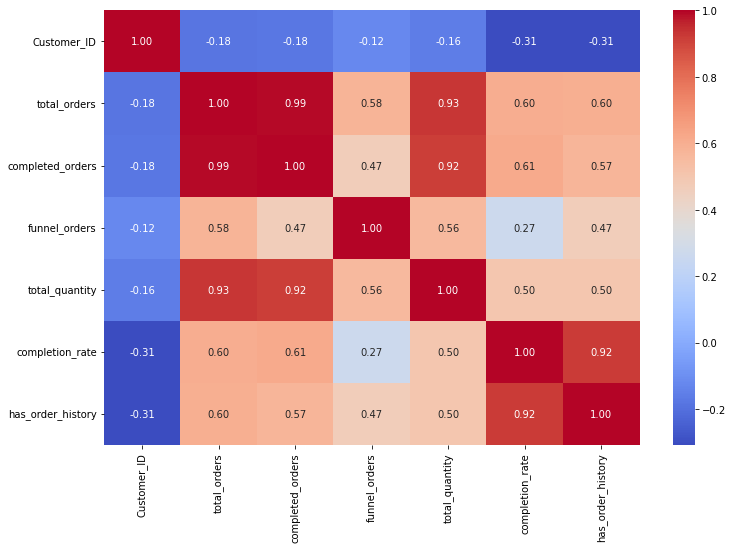

In [60]:
import seaborn as sns
import matplotlib.pyplot as plt

plt.figure(figsize=(12, 8))

sns.heatmap(
    corr_matrix,
    annot=True,
    cmap="coolwarm",
    fmt=".2f"
)

plt.show()

In [61]:
corr_matrix = final_df.select_dtypes(include="number").corr()

high_corr_pairs = []

for i in range(len(corr_matrix.columns)):
    for j in range(i + 1, len(corr_matrix.columns)):
        corr_value = corr_matrix.iloc[i, j]

        if abs(corr_value) >= 0.80:
            high_corr_pairs.append(
                (
                    corr_matrix.columns[i],
                    corr_matrix.columns[j],
                    corr_value
                )
            )

for pair in high_corr_pairs:
    print(pair)

('total_orders', 'completed_orders', 0.9912035921979738)
('total_orders', 'total_quantity', 0.9284434326799047)
('completed_orders', 'total_quantity', 0.917272639199026)
('completion_rate', 'has_order_history', 0.9231463728680361)


Q2: 
    
completed_orders retained as a candidate feature because it represents historical successful purchasing behavior; 
its high correlation with total_orders will be evaluated for multicollinearity and incremental predictive value 
before final model selection.

In [62]:
print(final_df.columns.tolist())

['Customer_ID', 'Account_Status', 'Is_National_Account', 'Is_Washington', 'Is_Tribal', 'Is_VLT', 'State_Code', 'Postal_Code', 'Country', 'Jurisdiction_Name', 'CBSA', 'Seasonality_Segment', 'Max_Quarter_Year_1', 'Max_Quarter_Year_2', 'EA_Segment', 'Revenue_Bucket', 'Profit_Bucket', 'Market_Share_Segment', 'Casino_Size_Segment', 'Market_Potential_Segment', 'Churn_Segment', 'Competitiveness_Flag', 'Volume_Segment', 'Density_Segment', 'Parent_Influence_Slots_Bucket', 'total_orders', 'completed_orders', 'funnel_orders', 'total_quantity', 'completion_rate', 'has_order_history']


In [63]:
candidate_features = [
    # Account / customer characteristics
    "Account_Status",
    "Is_National_Account",
    "Is_Washington",
    "Is_Tribal",
    "Is_VLT",

    # Geography
    "State_Code",
    "Jurisdiction_Name",

    # Behavioral / business segments
    "Seasonality_Segment",
    "EA_Segment",
    "Revenue_Bucket",
    "Profit_Bucket",
    "Market_Share_Segment",
    "Casino_Size_Segment",
    "Market_Potential_Segment",
    "Churn_Segment",
    "Competitiveness_Flag",
    "Volume_Segment",
    "Density_Segment",
    "Parent_Influence_Slots_Bucket",

    # Historical orders
    "total_orders",
    "completed_orders",
    "funnel_orders",
    "total_quantity",
    "has_order_history"
]

X = final_df[candidate_features]

In [64]:
print(sf_master_df.columns.tolist())

['Customer_ID', 'object_type', 'object_status', 'sent_to_socp_date', 'item_quantity']


In [65]:
print(sf_master_df["sent_to_socp_date"].head(10))

0    2018-07-31
1    2018-08-13
2    2018-09-10
3    2018-09-10
4    2018-09-10
6    2019-02-28
7    2019-02-28
8    2019-05-01
9    2019-09-27
10   2020-01-27
Name: sent_to_socp_date, dtype: datetime64[ns]


In [66]:
print(sf_master_df["sent_to_socp_date"].dtype)

datetime64[ns]


In [67]:
print(
    sf_master_df["sent_to_socp_date"].min(),
    sf_master_df["sent_to_socp_date"].max()
)

2017-06-09 00:00:00 2022-08-15 00:00:00


In [68]:
print(sf_master_df["object_status"].value_counts())
print(sf_master_df["object_type"].value_counts())

object_status
Completed    7972
Funnel       1054
Name: count, dtype: int64
object_type
Order    9026
Name: count, dtype: int64


In [69]:
"""
2017-06-09 ─────────────────────── 2022-08-15
        │              │                │
        │              │                │
     History       CUTOFF DATE       Future
     
     
2017-06-09 → 2021-08-15

We use this period to understand the customers past behaviour
"""

cutoff_date = pd.Timestamp("2021-08-15")

historical_orders = sf_master_df[
    sf_master_df["sent_to_socp_date"] <= cutoff_date
].copy()

print(historical_orders.shape)

(6433, 5)


In [70]:
historical_orders

,Customer_ID,object_type,object_status,sent_to_socp_date,item_quantity
0,280,Order,Completed,2018-07-31,2.0
1,280,Order,Completed,2018-08-13,2.0
2,280,Order,Completed,2018-09-10,4.0
3,280,Order,Completed,2018-09-10,8.0
4,280,Order,Completed,2018-09-10,6.0
...,...,...,...,...,...
9335,1263,Order,Funnel,2021-06-15,2.0
9336,332,Order,Completed,2019-10-30,14.0
9340,148,Order,Completed,2021-04-09,10.0
9344,966,Order,Completed,2019-10-15,3.0


In [71]:
customer_history = historical_orders.groupby("Customer_ID").agg(
    total_orders=("object_type", "count"),
    completed_orders=("object_status", lambda x: (x == "Completed").sum()),
    funnel_orders=("object_status", lambda x: (x == "Funnel").sum()),
    total_quantity=("item_quantity", "sum")
).reset_index()

In [72]:
customer_history

"""
History orders of the customer before cutoff date
"""

,Customer_ID,total_orders,completed_orders,funnel_orders,total_quantity
0,10,6,6,0,12.0
1,11,5,5,0,6.0
2,12,16,13,3,36.0
3,13,3,3,0,17.0
4,14,11,11,0,40.0
...,...,...,...,...,...
900,2796,9,9,0,30.0
901,2799,11,11,0,24.0
902,2800,10,10,0,19.0
903,2801,7,6,1,23.0


In [73]:
customer_history["has_order_history"] = 1

In [74]:
customer_history

,Customer_ID,total_orders,completed_orders,funnel_orders,total_quantity,has_order_history
0,10,6,6,0,12.0,1
1,11,5,5,0,6.0,1
2,12,16,13,3,36.0,1
3,13,3,3,0,17.0,1
4,14,11,11,0,40.0,1
...,...,...,...,...,...,...
900,2796,9,9,0,30.0,1
901,2799,11,11,0,24.0,1
902,2800,10,10,0,19.0,1
903,2801,7,6,1,23.0,1


In [75]:
model_df = final_df.drop(
    columns=[
        "total_orders",
        "completed_orders",
        "funnel_orders",
        "total_quantity",
        "has_order_history"
    ],
    errors="ignore"
).merge(
    customer_history,
    on="Customer_ID",
    how="left"
)

In [76]:
model_df.head()

,Customer_ID,Account_Status,Is_National_Account,Is_Washington,Is_Tribal,Is_VLT,State_Code,Postal_Code,Country,Jurisdiction_Name,...,Competitiveness_Flag,Volume_Segment,Density_Segment,Parent_Influence_Slots_Bucket,completion_rate,total_orders,completed_orders,funnel_orders,total_quantity,has_order_history
0,1,Active,False,False,False,False,ON,L5N 2W8,CAN,AGCO - Ontario,...,Yes,High,High,Medium Bucket,0.0,NaN,NaN,NaN,NaN,NaN
1,2,Active,False,False,False,True,LA,70053,USA,None,...,No,Medium,Medium,Low Bucket,0.0,NaN,NaN,NaN,NaN,NaN
2,3,Active,False,False,False,True,LA,70068,USA,None,...,No,Medium,Medium,Low Bucket,0.0,NaN,NaN,NaN,NaN,NaN
3,4,Active,False,False,False,False,NV,89521,USA,None,...,Yes,High,High,No bucket,0.0,NaN,NaN,NaN,NaN,NaN
4,5,Active,False,False,False,False,NV,89431,USA,None,...,Yes,High,High,No bucket,0.0,NaN,NaN,NaN,NaN,NaN


In [77]:
order_columns = [
    "total_orders",
    "completed_orders",
    "funnel_orders",
    "total_quantity",
    "has_order_history"
]

model_df[order_columns] = model_df[order_columns].fillna(0)

#As per our assumption customer who doesnt have order history his orders will be zero

In [78]:
model_df

,Customer_ID,Account_Status,Is_National_Account,Is_Washington,Is_Tribal,Is_VLT,State_Code,Postal_Code,Country,Jurisdiction_Name,...,Competitiveness_Flag,Volume_Segment,Density_Segment,Parent_Influence_Slots_Bucket,completion_rate,total_orders,completed_orders,funnel_orders,total_quantity,has_order_history
0,1,Active,False,False,False,False,ON,L5N 2W8,CAN,AGCO - Ontario,...,Yes,High,High,Medium Bucket,0.0,0.0,0.0,0.0,0.0,0.0
1,2,Active,False,False,False,True,LA,70053,USA,None,...,No,Medium,Medium,Low Bucket,0.0,0.0,0.0,0.0,0.0,0.0
2,3,Active,False,False,False,True,LA,70068,USA,None,...,No,Medium,Medium,Low Bucket,0.0,0.0,0.0,0.0,0.0,0.0
3,4,Active,False,False,False,False,NV,89521,USA,None,...,Yes,High,High,No bucket,0.0,0.0,0.0,0.0,0.0,0.0
4,5,Active,False,False,False,False,NV,89431,USA,None,...,Yes,High,High,No bucket,0.0,0.0,0.0,0.0,0.0,0.0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
3675,3676,Inactive,False,False,False,True,IL,60563,USA,None,...,Yes,High,Medium,Low Bucket,0.0,0.0,0.0,0.0,0.0,0.0
3676,3677,Inactive,False,False,False,False,NV,89117,USA,None,...,Yes,High,High,Low Bucket,0.0,0.0,0.0,0.0,0.0,0.0
3677,3678,Inactive,False,False,False,False,MI,49969,USA,Michigan - Tribal,...,No,Low,Unknown,Medium Bucket,0.0,0.0,0.0,0.0,0.0,0.0
3678,3679,Active,False,False,False,False,No Address Found,None,No Address Found,Pennsylvania,...,No,Unknown,Unknown,Medium Bucket,0.0,0.0,0.0,0.0,0.0,0.0


In [80]:
cutoff_date = pd.Timestamp("2021-08-15")

In [81]:
future_orders = sf_master_df[
    (sf_master_df["sent_to_socp_date"] > cutoff_date) &
    (sf_master_df["object_status"] == "Completed")
].copy()

print("Future completed orders:", len(future_orders))

Future completed orders: 1711


In [82]:
future_buyers = future_orders["Customer_ID"].unique()

print("Number of future buyers:", len(future_buyers))

Number of future buyers: 641


In [83]:
final_df["y"] = final_df["Customer_ID"].isin(future_buyers).astype(int)

In [84]:
final_df.head()

,Customer_ID,Account_Status,Is_National_Account,Is_Washington,Is_Tribal,Is_VLT,State_Code,Postal_Code,Country,Jurisdiction_Name,...,Volume_Segment,Density_Segment,Parent_Influence_Slots_Bucket,total_orders,completed_orders,funnel_orders,total_quantity,completion_rate,has_order_history,y
0,1,Active,False,False,False,False,ON,L5N 2W8,CAN,AGCO - Ontario,...,High,High,Medium Bucket,0.0,0.0,0.0,0.0,0.0,0,0
1,2,Active,False,False,False,True,LA,70053,USA,None,...,Medium,Medium,Low Bucket,0.0,0.0,0.0,0.0,0.0,0,0
2,3,Active,False,False,False,True,LA,70068,USA,None,...,Medium,Medium,Low Bucket,0.0,0.0,0.0,0.0,0.0,0,0
3,4,Active,False,False,False,False,NV,89521,USA,None,...,High,High,No bucket,0.0,0.0,0.0,0.0,0.0,0,0
4,5,Active,False,False,False,False,NV,89431,USA,None,...,High,High,No bucket,0.0,0.0,0.0,0.0,0.0,0,0


In [ ]:
"""
We have defined y as the target variable representing future purchase behavior.

y = 1 → Customer makes at least one Completed order after the cutoff date
y = 0 → Customer makes no Completed order after the cutoff date


BEFORE 15-Aug-2021                 AFTER 15-Aug-2021
──────────────────                 ──────────────────
Historical behavior                Future behavior
        ↓                                 ↓
        X                                 y
        │                                 │
        │                         Completed order?
        │                            ↙        ↘
        │                           YES        NO
        │                            ↓          ↓
        │                           y=1        y=0
        │
        └──────────────→ MODEL ←───────────────
                              ↓
                    Propensity Score
"""

In [85]:
print(model_df.columns.tolist())

['Customer_ID', 'Account_Status', 'Is_National_Account', 'Is_Washington', 'Is_Tribal', 'Is_VLT', 'State_Code', 'Postal_Code', 'Country', 'Jurisdiction_Name', 'CBSA', 'Seasonality_Segment', 'Max_Quarter_Year_1', 'Max_Quarter_Year_2', 'EA_Segment', 'Revenue_Bucket', 'Profit_Bucket', 'Market_Share_Segment', 'Casino_Size_Segment', 'Market_Potential_Segment', 'Churn_Segment', 'Competitiveness_Flag', 'Volume_Segment', 'Density_Segment', 'Parent_Influence_Slots_Bucket', 'completion_rate', 'total_orders', 'completed_orders', 'funnel_orders', 'total_quantity', 'has_order_history']


In [86]:
print(final_df.columns.tolist())

['Customer_ID', 'Account_Status', 'Is_National_Account', 'Is_Washington', 'Is_Tribal', 'Is_VLT', 'State_Code', 'Postal_Code', 'Country', 'Jurisdiction_Name', 'CBSA', 'Seasonality_Segment', 'Max_Quarter_Year_1', 'Max_Quarter_Year_2', 'EA_Segment', 'Revenue_Bucket', 'Profit_Bucket', 'Market_Share_Segment', 'Casino_Size_Segment', 'Market_Potential_Segment', 'Churn_Segment', 'Competitiveness_Flag', 'Volume_Segment', 'Density_Segment', 'Parent_Influence_Slots_Bucket', 'total_orders', 'completed_orders', 'funnel_orders', 'total_quantity', 'completion_rate', 'has_order_history', 'y']


In [87]:
candidate_features = [
    "Account_Status",
    "Is_National_Account",
    "Is_Washington",
    "Is_Tribal",
    "Is_VLT",

    "State_Code",
    "Jurisdiction_Name",

    "Seasonality_Segment",
    "Max_Quarter_Year_1",
    "Max_Quarter_Year_2",
    "EA_Segment",
    "Revenue_Bucket",
    "Profit_Bucket",
    "Market_Share_Segment",
    "Casino_Size_Segment",
    "Market_Potential_Segment",
    "Churn_Segment",
    "Competitiveness_Flag",
    "Volume_Segment",
    "Density_Segment",
    "Parent_Influence_Slots_Bucket",

    "total_orders",
    "completed_orders",
    "funnel_orders",
    "total_quantity",
    "has_order_history"
]

X = final_df[candidate_features]
y = final_df["y"]

In [89]:
drop_columns = [
    "Customer_ID",
    "Postal_Code",
    "Country",
    "completion_rate"
]


In [90]:
final_df = final_df.drop(columns=drop_columns)

In [91]:
categorical_investigate = [
    "Is_Washington",
    "CBSA",
    "Revenue_Bucket",
    "Profit_Bucket",
    "Market_Share_Segment",
    "Casino_Size_Segment",
    "Market_Potential_Segment",
    "Churn_Segment",
    "Competitiveness_Flag",
    "Volume_Segment",
    "Density_Segment",
    "Parent_Influence_Slots_Bucket"
]

for col in categorical_investigate:
    
    print("\n====================================")
    print(col)
    print("====================================")
    
    result = pd.crosstab(
        final_df[col],
        final_df["y"],
        normalize="index"
    ).round(3)
    
    print(result)


Is_Washington
y                  0      1
Is_Washington              
False          0.787  0.213
None           1.000  0.000
True           0.746  0.254

CBSA
y                                      0      1
CBSA                                           
Aberdeen, SD                       1.000  0.000
Aberdeen, WA                       0.933  0.067
Ada, OK                            0.947  0.053
Aguadilla-Isabela, PR              1.000  0.000
Akron, OH                          0.500  0.500
...                                  ...    ...
Yauco, PR                          0.000  1.000
York-Hanover, PA                   0.000  1.000
Youngstown-Warren-Boardman, OH-PA  0.000  1.000
Yuba City, CA                      0.000  1.000
Yuma, AZ                           0.500  0.500

[316 rows x 2 columns]

Revenue_Bucket
y                   0      1
Revenue_Bucket              
H               0.091  0.909
L               0.598  0.402
M               0.176  0.824
None            0.980  0.020



In [92]:
from scipy.stats import chi2_contingency

categorical_features = [
    "Is_Washington",
    "CBSA",
    "Revenue_Bucket",
    "Profit_Bucket",
    "Market_Share_Segment",
    "Casino_Size_Segment",
    "Market_Potential_Segment",
    "Churn_Segment",
    "Competitiveness_Flag",
    "Volume_Segment",
    "Density_Segment",
    "Parent_Influence_Slots_Bucket"
]

for col in categorical_features:
    
    table = pd.crosstab(
        final_df[col].fillna("Missing"),
        final_df["y"]
    )
    
    chi2, p_value, dof, expected = chi2_contingency(table)
    
    print(f"{col}:")
    print(f"Chi-square = {chi2:.4f}")
    print(f"p-value    = {p_value:.6f}")
    print("-" * 40)

Is_Washington:
Chi-square = 175.6840
p-value    = 0.000000
----------------------------------------
CBSA:
Chi-square = 809.0393
p-value    = 0.000000
----------------------------------------
Revenue_Bucket:
Chi-square = 1746.5174
p-value    = 0.000000
----------------------------------------
Profit_Bucket:
Chi-square = 1486.8681
p-value    = 0.000000
----------------------------------------
Market_Share_Segment:
Chi-square = 1355.0898
p-value    = 0.000000
----------------------------------------
Casino_Size_Segment:
Chi-square = 1465.5976
p-value    = 0.000000
----------------------------------------
Market_Potential_Segment:
Chi-square = 1462.1327
p-value    = 0.000000
----------------------------------------
Churn_Segment:
Chi-square = 1027.7008
p-value    = 0.000000
----------------------------------------
Competitiveness_Flag:
Chi-square = 43.5782
p-value    = 0.000000
----------------------------------------
Volume_Segment:
Chi-square = 124.6987
p-value    = 0.000000
------------

In [ ]:
"""
 Q2: Explain the approach to identif"For categorical variables, we performed a Chi-Square test of independence against the future-purchase target. Features with p-values below the chosen significance level of 0.05 showed statistically significant association with future purchase and were retained as candidate predictors for further evaluation."y feature selection from datasets and mention good statistical reasoning 
if suggesting to drop a feature.

 justification : "For categorical variables, we performed a Chi-Square test of independence against the future-purchase target. 
Features with p-values below the chosen significance level of 0.05 showed statistically significant association 
with future purchase and were retained as candidate predictors for further evaluation."
"""

In [93]:
drop_features = [
    "Customer_ID",
    "Postal_Code",
    "Country",
    "completion_rate"
]

X = X.drop(columns=drop_features, errors="ignore")

In [ ]:
"""

                    Candidate Feature
                           ↓
                  Is it an identifier?
                       ↙       ↘
                     YES       NO
                      ↓         ↓
                    DROP    Leakage check
                                ↓
                         Historical data?
                          ↙          ↘
                        NO           YES
                        ↓             ↓
                      DROP      Chi-Square test
                                      ↓
                                p-value < 0.05?
                                  ↙        ↘
                                NO         YES
                                ↓           ↓
                              DROP*     Candidate
                                            ↓
                                   Model evaluation


"""

In [95]:
print(y.value_counts())
print(y.value_counts(normalize=True).round(3))

y
0    3039
1     641
Name: count, dtype: int64
y
0    0.826
1    0.174
Name: proportion, dtype: float64


In [96]:
categorical_features = X.select_dtypes(
    include=["object", "category"]
).columns.tolist()

numerical_features = X.select_dtypes(
    include=["int64", "float64", "int32", "float32", "bool"]
).columns.tolist()

print("Categorical:", categorical_features)
print("Numerical:", numerical_features)

Categorical: ['Account_Status', 'Is_National_Account', 'Is_Washington', 'Is_Tribal', 'Is_VLT', 'State_Code', 'Jurisdiction_Name', 'Seasonality_Segment', 'Max_Quarter_Year_1', 'Max_Quarter_Year_2', 'EA_Segment', 'Revenue_Bucket', 'Profit_Bucket', 'Market_Share_Segment', 'Casino_Size_Segment', 'Market_Potential_Segment', 'Churn_Segment', 'Competitiveness_Flag', 'Volume_Segment', 'Density_Segment', 'Parent_Influence_Slots_Bucket']
Numerical: ['total_orders', 'completed_orders', 'funnel_orders', 'total_quantity', 'has_order_history']


In [97]:
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

print("X_train:", X_train.shape)
print("X_test :", X_test.shape)
print("y_train:", y_train.shape)
print("y_test :", y_test.shape)

X_train: (2944, 26)
X_test : (736, 26)
y_train: (2944,)
y_test : (736,)


In [100]:
from sklearn.preprocessing import OneHotEncoder

encoder = OneHotEncoder(
    handle_unknown="ignore",
    sparse_output=False
)

In [101]:
from sklearn.preprocessing import StandardScaler
from sklearn.compose import ColumnTransformer

preprocessor = ColumnTransformer(
    transformers=[
        ("num", StandardScaler(), numerical_features),
        ("cat", encoder, categorical_features)
    ]
)

In [102]:
from sklearn.linear_model import LogisticRegression
from sklearn.pipeline import Pipeline

model = Pipeline(
    steps=[
        ("preprocessor", preprocessor),
        ("classifier", LogisticRegression(
            max_iter=1000,
            random_state=42
        ))
    ]
)

In [103]:
model.fit(X_train, y_train)

Pipeline(steps=[('preprocessor',
                 ColumnTransformer(transformers=[('num', StandardScaler(),
                                                  ['total_orders',
                                                   'completed_orders',
                                                   'funnel_orders',
                                                   'total_quantity',
                                                   'has_order_history']),
                                                 ('cat',
                                                  OneHotEncoder(handle_unknown='ignore',
                                                                sparse_output=False),
                                                  ['Account_Status',
                                                   'Is_National_Account',
                                                   'Is_Washington', 'Is_Tribal',
                                                   'Is_VLT', 'State_Code',
                                                   'Jurisdiction_Na...
                                                   'Seasonality_Segment',
                                                   'Max_Quarter_Year_1',
                                                   'Max_Quarter_Year_2',
                                                   'EA_Segment',
                                                   'Revenue_Bucket',
                                                   'Profit_Bucket',
                                                   'Market_Share_Segment',
                                                   'Casino_Size_Segment',
                                                   'Market_Potential_Segment',
                                                   'Churn_Segment',
                                                   'Competitiveness_Flag',
                                                   'Volume_Segment',
                                                   'Density_Segment',
                                                   'Parent_Influence_Slots_Bucket'])])),
                ('classifier',
                 LogisticRegression(max_iter=1000, random_state=42))])

In [104]:
y_pred = model.predict(X_test)

In [105]:
y_prob = model.predict_proba(X_test)[:, 1]

In [106]:
from sklearn.metrics import accuracy_score, classification_report

print("Accuracy:", accuracy_score(y_test, y_pred))

print(classification_report(y_test, y_pred))

Accuracy: 0.9497282608695652
              precision    recall  f1-score   support

           0       0.96      0.98      0.97       608
           1       0.91      0.79      0.85       128

    accuracy                           0.95       736
   macro avg       0.93      0.89      0.91       736
weighted avg       0.95      0.95      0.95       736



In [107]:
from sklearn.metrics import roc_auc_score

auc = roc_auc_score(y_test, y_prob)

print("ROC-AUC:", auc)

ROC-AUC: 0.9866108141447367


In [108]:
# Calculate probability of future purchase for every customer
propensity_scores = model.predict_proba(X)[:, 1]

print(propensity_scores[:10])

[8.32764328e-04 6.31722597e-04 6.31722597e-04 1.85067802e-04
 1.85067802e-04 3.88224198e-04 4.77301041e-04 1.70294676e-04
 1.32740462e-04 9.49692587e-01]


In [109]:
final_df["Propensity_Score"] = propensity_scores

In [114]:
"""print(final_df[
    ["Customer_ID", "Propensity_Score"]
].head(10))"""


print(final_df.columns.tolist())

['Account_Status', 'Is_National_Account', 'Is_Washington', 'Is_Tribal', 'Is_VLT', 'State_Code', 'Jurisdiction_Name', 'CBSA', 'Seasonality_Segment', 'Max_Quarter_Year_1', 'Max_Quarter_Year_2', 'EA_Segment', 'Revenue_Bucket', 'Profit_Bucket', 'Market_Share_Segment', 'Casino_Size_Segment', 'Market_Potential_Segment', 'Churn_Segment', 'Competitiveness_Flag', 'Volume_Segment', 'Density_Segment', 'Parent_Influence_Slots_Bucket', 'total_orders', 'completed_orders', 'funnel_orders', 'total_quantity', 'has_order_history', 'y', 'Propensity_Score']


In [115]:
propensity_df["Customer_ID"]

0          1
1          2
2          3
3          4
4          5
        ... 
3675    3676
3676    3677
3677    3678
3678    3679
3679    3680
Name: Customer_ID, Length: 3680, dtype: int64

In [116]:
customer_ids = propensity_df["Customer_ID"].reset_index(drop=True)

In [117]:
final_propensity_df = pd.DataFrame({
    "Customer_ID": customer_ids,
    "Propensity_Score": final_df["Propensity_Score"].values
})

In [118]:
print(final_propensity_df.head())
print(final_propensity_df.shape)

   Customer_ID  Propensity_Score
0            1          0.000833
1            2          0.000632
2            3          0.000632
3            4          0.000185
4            5          0.000185
(3680, 2)


In [119]:
final_propensity_df["Propensity_%"] = (
    final_propensity_df["Propensity_Score"] * 100
).round(2)

In [120]:
score = final_propensity_df["Propensity_Score"]

summary_df = pd.DataFrame({
    "Statistical Measure": [
        "Number of Customers",
        "Mean",
        "Median",
        "Standard Deviation",
        "Minimum",
        "Q1 (25th Percentile)",
        "Q3 (75th Percentile)",
        "Maximum"
    ],
    
    "Value": [
        len(score),
        score.mean(),
        score.median(),
        score.std(),
        score.min(),
        score.quantile(0.25),
        score.quantile(0.75),
        score.max()
    ]
})

summary_df

,Statistical Measure,Value
0,Number of Customers,3680.000000
1,Mean,0.172580
2,Median,0.000470
3,Standard Deviation,0.323931
4,Minimum,0.000007
5,Q1 (25th Percentile),0.000163
6,Q3 (75th Percentile),0.164869
7,Maximum,1.000000


In [121]:
model_info = pd.DataFrame({
    "Metric": [
        "Model",
        "Problem Type",
        "Target",
        "Train/Test Split",
        "Accuracy",
        "ROC-AUC"
    ],
    
    "Value": [
        "Logistic Regression",
        "Binary Classification",
        "Future Completed Purchase",
        "80% / 20%",
        accuracy_score(y_test, y_pred),
        auc
    ]
})

model_info

,Metric,Value
0,Model,Logistic Regression
1,Problem Type,Binary Classification
2,Target,Future Completed Purchase
3,Train/Test Split,80% / 20%
4,Accuracy,0.949728
5,ROC-AUC,0.986611


In [122]:
with pd.ExcelWriter(
    "ProcDNA_Propensity_Score.xlsx",
    engine="openpyxl"
) as writer:

    # Customer-level scores
    final_propensity_df.to_excel(
        writer,
        sheet_name="Customer Propensity",
        index=False
    )

    # Statistical summary
    summary_df.to_excel(
        writer,
        sheet_name="Summary",
        index=False,
        startrow=1
    )

    # Model information
    model_info.to_excel(
        writer,
        sheet_name="Summary",
        index=False,
        startrow=12
    )

print("Excel file created successfully!")

Excel file created successfully!


In [123]:
# Statistical summary of propensity scores

score = final_propensity_df["Propensity_Score"]

print("Number of Customers:", len(score))
print("Mean:", score.mean())
print("Standard Deviation:", score.std())
print("Minimum:", score.min())
print("Q1:", score.quantile(0.25))
print("Median:", score.median())
print("Q3:", score.quantile(0.75))
print("Maximum:", score.max())

Number of Customers: 3680
Mean: 0.17258000548616878
Standard Deviation: 0.32393101478420044
Minimum: 6.969990019735686e-06
Q1: 0.00016261199618082097
Median: 0.00046952403590909647
Q3: 0.16486875517613886
Maximum: 0.9999999999866358


In [124]:
# Convert score to percentage

final_propensity_df["Propensity_%"] = (
    final_propensity_df["Propensity_Score"] * 100
).round(2)

In [125]:
Q1 = final_propensity_df["Propensity_Score"].quantile(0.25)
Q3 = final_propensity_df["Propensity_Score"].quantile(0.75)

print("Q1:", Q1)
print("Q3:", Q3)

Q1: 0.00016261199618082097
Q3: 0.16486875517613886


In [126]:
def assign_segment(score):
    if score <= Q1:
        return "Low"
    elif score <= Q3:
        return "Medium"
    else:
        return "High"

final_propensity_df["Propensity_Segment"] = (
    final_propensity_df["Propensity_Score"]
    .apply(assign_segment)
)

In [127]:
segment_counts = (
    final_propensity_df["Propensity_Segment"]
    .value_counts()
    .reindex(["Low", "Medium", "High"])
)

print(segment_counts)

Propensity_Segment
Low        920
Medium    1840
High       920
Name: count, dtype: int64


In [128]:
segment_summary = pd.DataFrame({
    "Segment": segment_counts.index,
    "Number_of_Customers": segment_counts.values
})

segment_summary["Percentage"] = (
    segment_summary["Number_of_Customers"]
    / len(final_propensity_df) * 100
).round(2)

print(segment_summary)

  Segment  Number_of_Customers  Percentage
0     Low                  920        25.0
1  Medium                 1840        50.0
2    High                  920        25.0


In [129]:
segment_counts = (
    final_propensity_df["Propensity_Segment"]
    .value_counts()
    .reindex(["Low", "Medium", "High"])
)

segment_summary = pd.DataFrame({
    "Segment": ["Low", "Medium", "High"],
    "Number_of_Customers": segment_counts.values,
    "Percentage": (
        segment_counts.values / len(final_propensity_df) * 100
    ).round(2)
})

segment_summary

,Segment,Number_of_Customers,Percentage
0,Low,920,25.0
1,Medium,1840,50.0
2,High,920,25.0


In [131]:
cutoff_summary = pd.DataFrame({
    "Statistic": [
        "Q1 (Low cutoff)",
        "Q3 (High cutoff)"
    ],
    "Value": [
        Q1,
        Q3
    ]
})

print(cutoff_summary)

          Statistic     Value
0   Q1 (Low cutoff)  0.000163
1  Q3 (High cutoff)  0.164869


In [132]:
with pd.ExcelWriter(
    "ProcDNA_Propensity_Score.xlsx",
    engine="openpyxl",
    mode="a",
    if_sheet_exists="replace"
) as writer:

    # Customer-level segmentation
    final_propensity_df.to_excel(
        writer,
        sheet_name="Propensity Segmentation",
        index=False
    )

    # Summary
    segment_summary.to_excel(
        writer,
        sheet_name="Propensity Segmentation",
        index=False,
        startrow=1
    )

    # Cutoffs
    cutoff_summary.to_excel(
        writer,
        sheet_name="Propensity Segmentation",
        index=False,
        startrow=7
    )

print("Q3 sheet added successfully!")

Q3 sheet added successfully!
